# UFC Rankings & Historical Analysis

Notebook de análisis histórico para **UFC_PREDICTOR** — versión **CSV-only** (sin Parquet).

## Qué construye

- Ranking histórico por **Peak General Elo**.
- Ranking actual por Elo.
- P4P actual basado en Elo.
- P4P histórico basado en Elo.
- Rankings actuales por categoría de peso.
- Rankings históricos por categoría de peso.
- Evolución temporal del Elo.
- Timeline del #1 P4P del modelo.
- Peleas de campeonato y victorias en `Title Bout`.
- Campeones históricos detectables a partir de victorias en peleas por el cinturón.
- Campeones / peleadores por país y región cuando se dispone de geografía.
- Récords y curiosidades: mayores upsets, mayores saltos de Elo, rachas, etc.

> **P4P del modelo:** no es el ranking oficial de UFC. Es un ranking analítico del proyecto, basado exclusivamente en el General Elo.

> **País/región:** `fighters_clean.parquet` no contiene actualmente nacionalidad en el pipeline base. El notebook detecta columnas geográficas si se añaden en el futuro y, alternativamente, permite usar `data/external/fighter_geography.csv`.

> Esta versión evita completamente `pyarrow` / `fastparquet` y reconstruye el General Elo directamente desde los CSV brutos.

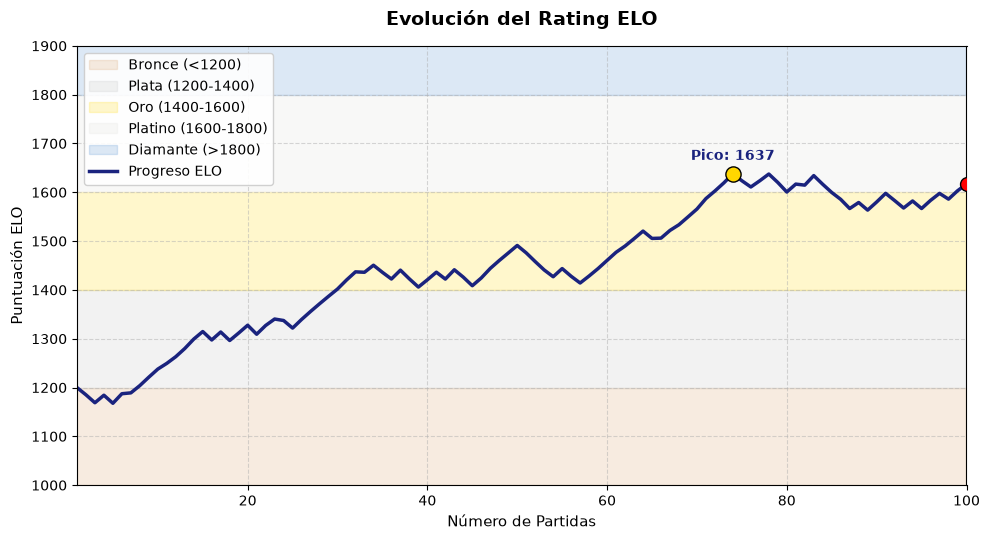

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Generación de datos simulados
np.random.seed(42)
n_games = 100
matches = np.arange(1, n_games + 1)

elo = [1200]
k_factor = 32

for i in range(1, n_games):
    opponent_elo = elo[-1] + np.random.normal(0, 50)
    expected_score = 1 / (1 + 10 ** ((opponent_elo - elo[-1]) / 400))
    result = np.random.choice([1, 0, 0.5], p=[0.55, 0.38, 0.07])
    new_elo = elo[-1] + k_factor * (result - expected_score)
    elo.append(new_elo)

elo = np.array(elo)

# 2. Configuración de la figura
plt.figure(figsize=(10, 5.5))

# Franjas de categoría (Rangos)
plt.axhspan(1000, 1200, color='#cd7f32', alpha=0.15, label='Bronce (<1200)')
plt.axhspan(1200, 1400, color='#c0c0c0', alpha=0.20, label='Plata (1200-1400)')
plt.axhspan(1400, 1600, color='#ffd700', alpha=0.20, label='Oro (1400-1600)')
plt.axhspan(1600, 1800, color='#e5e4e2', alpha=0.25, label='Platino (1600-1800)')
plt.axhspan(1800, 2000, color='#1565c0', alpha=0.15, label='Diamante (>1800)')

# Trazo del ELO
plt.plot(matches, elo, color='#1a237e', linewidth=2.5, label='Progreso ELO')

# Marcar Pico Máximo y Estado Actual
peak_idx = np.argmax(elo)
plt.scatter(matches[peak_idx], elo[peak_idx], color='gold', edgecolor='black', s=120, zorder=5)
plt.scatter(matches[-1], elo[-1], color='red', edgecolor='black', s=100, zorder=5)

plt.annotate(f'Pico: {int(elo[peak_idx])}', (matches[peak_idx], elo[peak_idx]), 
             textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold', color='#1a237e')

# Ajustes estéticos
plt.title('Evolución del Rating ELO', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Partidas', fontsize=11)
plt.ylabel('Puntuación ELO', fontsize=11)
plt.xlim(1, n_games)
plt.ylim(1000, 1900)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', framealpha=0.9)

plt.tight_layout()
plt.show()

## 1. Imports y configuración

In [1]:
from __future__ import annotations

from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ------------------------------------------------------------
# Configuración del análisis
# ------------------------------------------------------------
TOP_N = 15

# "Activo" = ha tenido una pelea resuelta dentro de esta ventana.
ACTIVE_WINDOW_DAYS = 730

# Evita que alguien con una sola pelea aparezca demasiado arriba
# en rankings denominados "actuales".
MIN_FIGHTS_CURRENT = 2

# Configuración REAL del General Elo del proyecto (elo_v2_final_raw)
BASE_ELO = 1500.0
ELO_SCALE = 300.0

K_SCHEDULE = (
    (3, 30.0),       # 0-2 peleas UFC previas
    (6, 28.0),       # 3-5
    (10, 24.0),      # 6-9
    (math.inf, 20.0) # 10+
)

## 2. Localizar automáticamente la raíz del proyecto

El notebook puede abrirse desde `notebooks/` o desde la raíz de `UFC_PREDICTOR`.

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate

    raise FileNotFoundError(
        "No se ha encontrado la raíz de UFC_PREDICTOR. "
        "Ejecuta el notebook dentro del repositorio."
    )


PROJECT_ROOT = find_project_root()

INTERIM_DIR = PROJECT_ROOT / "data" / "interim" / "ufcstats"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "ufcstats"
EXTERNAL_DIR = PROJECT_ROOT / "data" / "external"

FIGHTS_PATH = INTERIM_DIR / "fights_clean.parquet"
FIGHTERS_PATH = INTERIM_DIR / "fighters_clean.parquet"
FIGHTER_SNAPSHOTS_PATH = PROCESSED_DIR / "fighter_snapshots.parquet"
ELO_SNAPSHOTS_PATH = PROCESSED_DIR / "fighter_elo_snapshots.parquet"

required_paths = [
    FIGHTS_PATH,
    FIGHTERS_PATH,
    FIGHTER_SNAPSHOTS_PATH,
    ELO_SNAPSHOTS_PATH,
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Falta el archivo requerido: {path}")

print("PROJECT_ROOT:", PROJECT_ROOT)

PROJECT_ROOT: C:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR


## 3. Cargar datos directamente desde CSV

Esta versión del notebook **no utiliza Parquet**.

Lee directamente:

- `data/raw/ufcstats/fights.csv`
- `data/raw/ufcstats/fighters.csv`

y reconstruye el **General Elo `elo_v2_final_raw`** desde cero en memoria.

Esto evita completamente `pyarrow`, `fastparquet`, `cramjam` y cualquier DLL nativa asociada a Parquet.


In [3]:

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "ufcstats"

FIGHTS_CSV = RAW_DIR / "fights.csv"
FIGHTERS_CSV = RAW_DIR / "fighters.csv"

for path in [FIGHTS_CSV, FIGHTERS_CSV]:
    if not path.exists():
        raise FileNotFoundError(f"Falta el archivo requerido: {path}")

# dtype=str conserva IDs y evita conversiones inesperadas.
fights = pd.read_csv(FIGHTS_CSV, dtype=str, low_memory=False)
fighters = pd.read_csv(FIGHTERS_CSV, dtype=str, low_memory=False)

print(f"Fights raw:   {len(fights):,}")
print(f"Fighters raw: {len(fighters):,}")

display(fights.head(3))


Fights raw:   8,949
Fighters raw: 2,769


,fight_id,event_id,event_name,event_date,event_location,event_url,fight_order,fight_url,fighter_1_id,fighter_1_name,fighter_1_url,fighter_1_result,fighter_2_id,fighter_2_name,fighter_2_url,fighter_2_result,winner_id,fighter_1_knockdowns,fighter_2_knockdowns,fighter_1_sig_strikes,fighter_2_sig_strikes,fighter_1_takedowns,fighter_2_takedowns,fighter_1_submission_attempts,fighter_2_submission_attempts,weight_class,method,method_details,finish_round,finish_time
0,701c97405da76603,f354c50b8d63d9b3,UFC Fight Night: Du Plessis vs. Usman,2026-07-18,"Oklahoma City, Oklahoma, USA",http://ufcstats.com/event-details/f354c50b8d63...,1,http://ufcstats.com/fight-details/701c97405da7...,0d7b51c9d2649a6e,Dricus Du Plessis,http://ufcstats.com/fighter-details/0d7b51c9d2...,W,f1b2aa7853d1ed6e,Kamaru Usman,http://ufcstats.com/fighter-details/f1b2aa7853...,L,0d7b51c9d2649a6e,0,0,136,92,0,0,0,0,Middleweight,U-DEC,NaN,5,5:00
1,4eff5a845db17572,f354c50b8d63d9b3,UFC Fight Night: Du Plessis vs. Usman,2026-07-18,"Oklahoma City, Oklahoma, USA",http://ufcstats.com/event-details/f354c50b8d63...,2,http://ufcstats.com/fight-details/4eff5a845db1...,a93f94c923c3a9cb,Christian Leroy Duncan,http://ufcstats.com/fighter-details/a93f94c923...,W,13a0275fa13c4d26,Jared Cannonier,http://ufcstats.com/fighter-details/13a0275fa1...,L,a93f94c923c3a9cb,0,0,68,15,1,5,0,0,Middleweight,U-DEC,NaN,3,5:00
2,f2abca7379982d4f,f354c50b8d63d9b3,UFC Fight Night: Du Plessis vs. Usman,2026-07-18,"Oklahoma City, Oklahoma, USA",http://ufcstats.com/event-details/f354c50b8d63...,3,http://ufcstats.com/fight-details/f2abca737998...,971246648e162f0d,Chase Hooper,http://ufcstats.com/fighter-details/971246648e...,W,e99eb0ef25885de5,Mitch Ramirez,http://ufcstats.com/fighter-details/e99eb0ef25...,L,971246648e162f0d,0,0,3,1,1,0,1,0,Lightweight,SUB,Rear Naked Choke,1,2:15


In [4]:

def normalize_optional_string(value):
    if pd.isna(value):
        return pd.NA
    value = str(value).strip()
    return value if value else pd.NA


def normalize_result(value):
    if pd.isna(value):
        return pd.NA

    text = str(value).strip().upper()

    aliases = {
        "W": "W",
        "WIN": "W",
        "WINNER": "W",
        "L": "L",
        "LOSS": "L",
        "LOSER": "L",
        "D": "D",
        "DRAW": "D",
        "NC": "NC",
        "N/C": "NC",
        "NO CONTEST": "NC",
        "NO-CONTEST": "NC",
    }

    return aliases.get(text, text)


required_fight_columns = {
    "fight_id",
    "event_id",
    "event_date",
    "fighter_1_id",
    "fighter_1_name",
    "fighter_1_result",
    "fighter_2_id",
    "fighter_2_name",
    "fighter_2_result",
    "winner_id",
    "weight_class",
}

missing = required_fight_columns - set(fights.columns)
if missing:
    raise ValueError(f"fights.csv: faltan columnas {sorted(missing)}")

# Limpieza mínima necesaria para este notebook.
fights["event_date"] = pd.to_datetime(
    fights["event_date"],
    errors="raise",
)

for col in [
    "fight_id",
    "event_id",
    "fighter_1_id",
    "fighter_1_name",
    "fighter_2_id",
    "fighter_2_name",
    "winner_id",
    "weight_class",
]:
    if col in fights.columns:
        fights[col] = fights[col].map(normalize_optional_string).astype("string")

fights["fighter_1_result"] = (
    fights["fighter_1_result"].map(normalize_result).astype("string")
)
fights["fighter_2_result"] = (
    fights["fighter_2_result"].map(normalize_result).astype("string")
)

if "fight_order" in fights.columns:
    fights["fight_order"] = pd.to_numeric(
        fights["fight_order"],
        errors="coerce",
    ).astype("Int64")
else:
    # Fallback estable si un scraping antiguo no tiene fight_order.
    fights["fight_order"] = pd.Series(
        np.arange(len(fights)),
        index=fights.index,
        dtype="Int64",
    )

if "event_name" not in fights.columns:
    fights["event_name"] = pd.NA

if "bout_type" not in fights.columns:
    fights["bout_type"] = pd.NA

print("Rango de fechas:", fights["event_date"].min().date(), "→", fights["event_date"].max().date())


Rango de fechas: 1994-03-11 → 2026-11-07


## 4. Reconstruir el General Elo directamente desde `fights.csv`

Usamos la misma configuración del proyecto:

\[
E_A = \frac{1}{1 + 10^{(R_B-R_A)/300}}
\]

\[
R'_A = R_A + K_A(S_A-E_A)
\]

con:

- Elo inicial = `1500`
- escala = `300`
- K = `30 / 28 / 24 / 20` según experiencia previa
- W = `1.0`
- L = `0.0`
- D = `0.5`
- NC = no actualiza Elo

El estado se actualiza **después** de guardar los valores pre-fight de cada combate.


In [5]:

def k_factor(fights_before: int) -> float:
    for upper_bound, value in K_SCHEDULE:
        if fights_before < upper_bound:
            return value
    raise RuntimeError("K schedule inválido")


def expected_score(rating_a: float, rating_b: float) -> float:
    return float(
        1.0 / (1.0 + 10.0 ** ((rating_b - rating_a) / ELO_SCALE))
    )


def actual_score(result: str):
    mapping = {
        "W": 1.0,
        "L": 0.0,
        "D": 0.5,
    }
    return mapping.get(result)


# Mismo orden cronológico usado por el pipeline.
fights_sorted = (
    fights
    .sort_values(
        ["event_date", "event_id", "fight_order"],
        ascending=[True, True, False],
        na_position="last",
        kind="stable",
    )
    .reset_index(drop=True)
)

states = {}
records = []

def new_state():
    return {
        "elo": BASE_ELO,
        "fights": 0,
        "wins": 0,
        "losses": 0,
        "draws": 0,
        "no_contests": 0,
        "win_streak": 0,
        "loss_streak": 0,
        "last_fight_date": None,
    }

for fight in fights_sorted.itertuples(index=False):
    f1_id = str(fight.fighter_1_id)
    f2_id = str(fight.fighter_2_id)

    # Ignoramos filas sin IDs válidos.
    if f1_id in {"<NA>", "nan", "None"} or f2_id in {"<NA>", "nan", "None"}:
        continue

    s1 = states.setdefault(f1_id, new_state())
    s2 = states.setdefault(f2_id, new_state())

    r1 = normalize_result(fight.fighter_1_result)
    r2 = normalize_result(fight.fighter_2_result)

    elo1_before = float(s1["elo"])
    elo2_before = float(s2["elo"])

    exp1 = expected_score(elo1_before, elo2_before)
    exp2 = 1.0 - exp1

    k1 = k_factor(s1["fights"])
    k2 = k_factor(s2["fights"])

    score1 = actual_score(r1)
    score2 = actual_score(r2)

    # Futuras/no resueltas y NC no actualizan General Elo.
    if score1 is not None and score2 is not None:
        elo1_after = elo1_before + k1 * (score1 - exp1)
        elo2_after = elo2_before + k2 * (score2 - exp2)
    else:
        elo1_after = elo1_before
        elo2_after = elo2_before

    common = {
        "fight_id": fight.fight_id,
        "event_id": fight.event_id,
        "event_name": getattr(fight, "event_name", pd.NA),
        "event_date": pd.Timestamp(fight.event_date),
        "fight_order": fight.fight_order,
        "weight_class": fight.weight_class,
        "bout_type": getattr(fight, "bout_type", pd.NA),
        "winner_id": fight.winner_id,
    }

    records.append({
        **common,
        "fighter_id": f1_id,
        "fighter_name": fight.fighter_1_name,
        "opponent_id": f2_id,
        "opponent_name": fight.fighter_2_name,
        "result": r1,
        "fights_before": s1["fights"],
        "wins_before": s1["wins"],
        "losses_before": s1["losses"],
        "draws_before": s1["draws"],
        "no_contests_before": s1["no_contests"],
        "current_win_streak_before": s1["win_streak"],
        "current_loss_streak_before": s1["loss_streak"],
        "elo_general_raw_before": elo1_before,
        "opponent_elo_before": elo2_before,
        "expected_score": exp1,
        "k_factor": k1,
        "elo_general_raw_after": elo1_after,
        "elo_change": elo1_after - elo1_before,
    })

    records.append({
        **common,
        "fighter_id": f2_id,
        "fighter_name": fight.fighter_2_name,
        "opponent_id": f1_id,
        "opponent_name": fight.fighter_1_name,
        "result": r2,
        "fights_before": s2["fights"],
        "wins_before": s2["wins"],
        "losses_before": s2["losses"],
        "draws_before": s2["draws"],
        "no_contests_before": s2["no_contests"],
        "current_win_streak_before": s2["win_streak"],
        "current_loss_streak_before": s2["loss_streak"],
        "elo_general_raw_before": elo2_before,
        "opponent_elo_before": elo1_before,
        "expected_score": exp2,
        "k_factor": k2,
        "elo_general_raw_after": elo2_after,
        "elo_change": elo2_after - elo2_before,
    })

    # Solo las peleas con resultado conocido cuentan como experiencia.
    resolved_pair = (
        r1 in {"W", "L", "D", "NC"}
        and r2 in {"W", "L", "D", "NC"}
    )

    if resolved_pair:
        s1["elo"] = elo1_after
        s2["elo"] = elo2_after

        for state, result in [(s1, r1), (s2, r2)]:
            state["fights"] += 1
            state["last_fight_date"] = pd.Timestamp(fight.event_date)

            if result == "W":
                state["wins"] += 1
                state["win_streak"] += 1
                state["loss_streak"] = 0
            elif result == "L":
                state["losses"] += 1
                state["loss_streak"] += 1
                state["win_streak"] = 0
            elif result == "D":
                state["draws"] += 1
                state["win_streak"] = 0
                state["loss_streak"] = 0
            elif result == "NC":
                state["no_contests"] += 1
                # Mantener rachas en NC evita tratarlo como victoria/derrota.

ratings = pd.DataFrame(records)

ratings["is_resolved"] = ratings["result"].isin(["W", "L", "D", "NC"])

ratings["win_streak_after"] = np.where(
    ratings["result"].eq("W"),
    ratings["current_win_streak_before"].astype(float) + 1,
    ratings["current_win_streak_before"].astype(float),
)

print(f"Filas fighter-fight reconstruidas: {len(ratings):,}")
print(f"Peleadores con estado Elo: {ratings['fighter_id'].nunique():,}")

display(
    ratings[
        [
            "event_date",
            "fighter_name",
            "opponent_name",
            "result",
            "fights_before",
            "elo_general_raw_before",
            "expected_score",
            "elo_change",
            "elo_general_raw_after",
        ]
    ].head(10)
)


Filas fighter-fight reconstruidas: 17,898
Peleadores con estado Elo: 2,769


,event_date,fighter_name,opponent_name,result,fights_before,elo_general_raw_before,expected_score,elo_change,elo_general_raw_after
0,1994-03-11,Scott Morris,Sean Daugherty,W,0,"1,500.00",0.50,15.00,"1,515.00"
1,1994-03-11,Sean Daugherty,Scott Morris,L,0,"1,500.00",0.50,-15.00,"1,485.00"
2,1994-03-11,Patrick Smith,Ray Wizard,W,0,"1,500.00",0.50,15.00,"1,515.00"
3,1994-03-11,Ray Wizard,Patrick Smith,L,0,"1,500.00",0.50,-15.00,"1,485.00"
4,1994-03-11,Johnny Rhodes,David Levicki,W,0,"1,500.00",0.50,15.00,"1,515.00"
5,1994-03-11,David Levicki,Johnny Rhodes,L,0,"1,500.00",0.50,-15.00,"1,485.00"
6,1994-03-11,Frank Hamaker,Thaddeus Luster,W,0,"1,500.00",0.50,15.00,"1,515.00"
7,1994-03-11,Thaddeus Luster,Frank Hamaker,L,0,"1,500.00",0.50,-15.00,"1,485.00"
8,1994-03-11,Orlando Wiet,Robert Lucarelli,W,0,"1,500.00",0.50,15.00,"1,515.00"
9,1994-03-11,Robert Lucarelli,Orlando Wiet,L,0,"1,500.00",0.50,-15.00,"1,485.00"


## 5. Historial de Elo

Para los rankings históricos usamos **Elo posterior a pelea**, no el 1500 inicial antes del debut. Así el peak representa un nivel alcanzado tras competir.

In [6]:
resolved = ratings[ratings["is_resolved"]].copy()

post_points = resolved[
    [
        "fighter_id", "fighter_name",
        "event_date", "event_name", "fight_id",
        "weight_class", "opponent_id", "opponent_name",
        "fights_before", "elo_general_raw_after",
    ]
].rename(columns={"elo_general_raw_after": "elo"})

post_points["ufc_fights_after"] = (
    post_points["fights_before"].astype(int) + 1
)

post_points["elo"] = post_points["elo"].astype(float)

print(f"Puntos post-fight de Elo: {len(post_points):,}")
display(post_points.head())

Puntos post-fight de Elo: 17,774


,fighter_id,fighter_name,event_date,event_name,fight_id,weight_class,opponent_id,opponent_name,fights_before,elo,ufc_fights_after
0,be9d259be012e8a4,Scott Morris,1994-03-11,UFC 2: No Way Out,4acab67848e78327,Open Weight,a683f9ddb70aa4bd,Sean Daugherty,0,"1,515.00",1
1,a683f9ddb70aa4bd,Sean Daugherty,1994-03-11,UFC 2: No Way Out,4acab67848e78327,Open Weight,be9d259be012e8a4,Scott Morris,0,"1,485.00",1
2,46c8ec317aff28ac,Patrick Smith,1994-03-11,UFC 2: No Way Out,4b9ae533ccb3fcdf,Open Weight,ea0ad155451ed1f5,Ray Wizard,0,"1,515.00",1
3,ea0ad155451ed1f5,Ray Wizard,1994-03-11,UFC 2: No Way Out,4b9ae533ccb3fcdf,Open Weight,46c8ec317aff28ac,Patrick Smith,0,"1,485.00",1
4,319fa1bd3176bded,Johnny Rhodes,1994-03-11,UFC 2: No Way Out,ccee020be2e8d9f6,Open Weight,49590e0508b2c19f,David Levicki,0,"1,515.00",1


## 6. Top histórico por Peak Elo

In [7]:
peak_idx = post_points.groupby("fighter_id")["elo"].idxmax()

historical_peak = (
    post_points.loc[peak_idx]
    .rename(columns={
        "elo": "peak_elo",
        "event_date": "peak_date",
        "event_name": "peak_event",
        "weight_class": "peak_weight_class",
        "opponent_name": "peak_opponent",
    })
    [
        [
            "fighter_id", "fighter_name", "peak_elo",
            "peak_date", "peak_weight_class",
            "peak_event", "peak_opponent",
            "ufc_fights_after",
        ]
    ]
    .sort_values(
        ["peak_elo", "peak_date"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

historical_peak.insert(
    0,
    "rank",
    np.arange(1, len(historical_peak) + 1),
)

display(historical_peak.head(TOP_N))

,rank,fighter_id,fighter_name,peak_elo,peak_date,peak_weight_class,peak_event,peak_opponent,ufc_fights_after
0,1,07f72a2a7591b409,Jon Jones,"1,701.16",2024-11-16,Heavyweight,UFC 309: Jones vs. Miocic,Stipe Miocic,24
1,2,275aca31f61ba28c,Islam Makhachev,"1,682.57",2026-08-15,Welterweight,UFC 330: Makhachev vs. Machado Garry,Ian Machado Garry,19
2,3,6506c1d34da9c013,Georges St-Pierre,"1,676.74",2017-11-04,Middleweight,UFC 217: Bisping vs. St-Pierre,Michael Bisping,22
3,4,f1b2aa7853d1ed6e,Kamaru Usman,"1,669.73",2021-11-06,Welterweight,UFC 268: Usman vs. Covington 2,Colby Covington,15
4,5,1f454354805b6f75,Anderson Silva,"1,666.87",2012-10-13,Light Heavyweight,UFC 153: Silva vs Bonnar,Stephan Bonnar,16
5,6,e1248941344b3288,Alexander Volkanovski,"1,651.20",2022-07-02,Featherweight,UFC 276: Adesanya vs. Cannonier,Max Holloway,12
6,7,032cc3922d871c7f,Khabib Nurmagomedov,"1,649.41",2020-10-24,Lightweight,UFC 254: Khabib vs. Gaethje,Justin Gaethje,13
7,8,22a92d7f62195791,Tony Ferguson,"1,645.39",2019-06-08,Lightweight,UFC 238: Cejudo vs. Moraes,Donald Cerrone,16
8,9,029eaff01e6bb8f0,Dustin Poirier,"1,642.30",2021-07-10,Lightweight,UFC 264: Poirier vs. McGregor 3,Conor McGregor,26
9,10,150ff4cc642270b9,Max Holloway,"1,641.40",2024-04-13,Lightweight,UFC 300: Pereira vs. Hill,Justin Gaethje,29


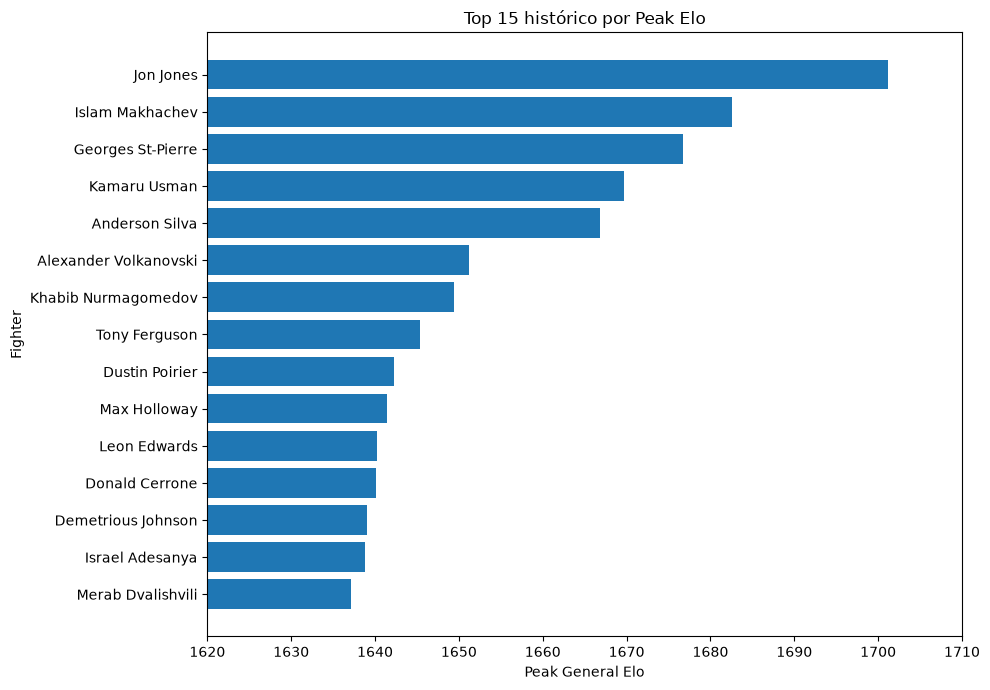

In [19]:
top_hist = historical_peak.head(TOP_N).sort_values("peak_elo")

plt.figure(figsize=(10, 7))
plt.barh(top_hist["fighter_name"], top_hist["peak_elo"])
plt.xlim(1620, 1710)
plt.xlabel("Peak General Elo")
plt.ylabel("Fighter")
plt.title(f"Top {TOP_N} histórico por Peak Elo")
plt.tight_layout()
plt.show()

## 7. Ranking actual por Elo

Se toma el Elo **posterior a la última pelea resuelta** de cada peleador.

Para el ranking denominado “actual” filtramos luchadores cuya última pelea esté dentro de los últimos `ACTIVE_WINDOW_DAYS` días respecto a la pelea resuelta más reciente del dataset.

In [9]:
latest_resolved_date = resolved["event_date"].max()
active_cutoff = (
    latest_resolved_date
    - pd.Timedelta(days=ACTIVE_WINDOW_DAYS)
)

current = (
    resolved
    .sort_values(
        ["fighter_id", "event_date", "event_id", "fight_order"],
        kind="stable",
    )
    .groupby("fighter_id", as_index=False)
    .tail(1)
    .copy()
)

current = current.rename(columns={
    "elo_general_raw_after": "current_elo",
    "event_date": "last_fight_date",
    "weight_class": "current_weight_class",
})

current["ufc_fights"] = (
    current["fights_before"].astype(int) + 1
)

current["is_active"] = (
    current["last_fight_date"] >= active_cutoff
)

current = current[
    [
        "fighter_id", "fighter_name",
        "current_elo", "current_weight_class",
        "last_fight_date", "ufc_fights", "is_active",
    ]
]

current_active = (
    current[
        current["is_active"]
        & current["ufc_fights"].ge(MIN_FIGHTS_CURRENT)
    ]
    .sort_values("current_elo", ascending=False)
    .reset_index(drop=True)
)

current_active.insert(
    0,
    "rank",
    np.arange(1, len(current_active) + 1),
)

print("Última pelea resuelta:", latest_resolved_date.date())
print("Corte de actividad:", active_cutoff.date())
print("Peleadores activos elegibles:", len(current_active))

display(current_active.head(TOP_N))

Última pelea resuelta: 2026-09-12
Corte de actividad: 2024-09-12
Peleadores activos elegibles: 715


,rank,fighter_id,fighter_name,current_elo,current_weight_class,last_fight_date,ufc_fights,is_active
0,1,07f72a2a7591b409,Jon Jones,"1,701.16",Heavyweight,2024-11-16,24,True
1,2,275aca31f61ba28c,Islam Makhachev,"1,682.57",Welterweight,2026-08-15,19,True
2,3,e1248941344b3288,Alexander Volkanovski,"1,642.25",Featherweight,2026-01-31,18,True
3,4,150ff4cc642270b9,Max Holloway,"1,637.70",Welterweight,2026-07-11,33,True
4,5,07225ba28ae309b6,Charles Oliveira,"1,636.12",Lightweight,2026-03-07,37,True
5,6,76e2870ffafbe38f,Movsar Evloev,"1,631.95",Featherweight,2026-03-21,10,True
6,7,cb696ebfb6598724,Aljamain Sterling,"1,631.89",Featherweight,2026-04-25,23,True
7,8,f1b2aa7853d1ed6e,Kamaru Usman,"1,630.82",Middleweight,2026-07-18,20,True
8,9,0d7b51c9d2649a6e,Dricus Du Plessis,"1,628.63",Middleweight,2026-07-18,11,True
9,10,132deb59abae64b1,Valentina Shevchenko,"1,626.48",Women's Flyweight,2025-11-15,19,True


## 8. P4P actual del modelo

El P4P del modelo es simplemente el ranking de luchadores activos por General Elo, independientemente de la categoría.

In [10]:
p4p_current = current_active.copy()

display(
    p4p_current[
        [
            "rank", "fighter_name", "current_elo",
            "current_weight_class", "last_fight_date",
            "ufc_fights",
        ]
    ].head(TOP_N)
)

,rank,fighter_name,current_elo,current_weight_class,last_fight_date,ufc_fights
0,1,Jon Jones,"1,701.16",Heavyweight,2024-11-16,24
1,2,Islam Makhachev,"1,682.57",Welterweight,2026-08-15,19
2,3,Alexander Volkanovski,"1,642.25",Featherweight,2026-01-31,18
3,4,Max Holloway,"1,637.70",Welterweight,2026-07-11,33
4,5,Charles Oliveira,"1,636.12",Lightweight,2026-03-07,37
5,6,Movsar Evloev,"1,631.95",Featherweight,2026-03-21,10
6,7,Aljamain Sterling,"1,631.89",Featherweight,2026-04-25,23
7,8,Kamaru Usman,"1,630.82",Middleweight,2026-07-18,20
8,9,Dricus Du Plessis,"1,628.63",Middleweight,2026-07-18,11
9,10,Valentina Shevchenko,"1,626.48",Women's Flyweight,2025-11-15,19


## 9. P4P histórico del modelo

In [11]:
p4p_historical = historical_peak.copy()

display(
    p4p_historical[
        [
            "rank", "fighter_name", "peak_elo",
            "peak_date", "peak_weight_class",
            "peak_opponent",
        ]
    ].head(TOP_N)
)

,rank,fighter_name,peak_elo,peak_date,peak_weight_class,peak_opponent
0,1,Jon Jones,"1,701.16",2024-11-16,Heavyweight,Stipe Miocic
1,2,Islam Makhachev,"1,682.57",2026-08-15,Welterweight,Ian Machado Garry
2,3,Georges St-Pierre,"1,676.74",2017-11-04,Middleweight,Michael Bisping
3,4,Kamaru Usman,"1,669.73",2021-11-06,Welterweight,Colby Covington
4,5,Anderson Silva,"1,666.87",2012-10-13,Light Heavyweight,Stephan Bonnar
5,6,Alexander Volkanovski,"1,651.20",2022-07-02,Featherweight,Max Holloway
6,7,Khabib Nurmagomedov,"1,649.41",2020-10-24,Lightweight,Justin Gaethje
7,8,Tony Ferguson,"1,645.39",2019-06-08,Lightweight,Donald Cerrone
8,9,Dustin Poirier,"1,642.30",2021-07-10,Lightweight,Conor McGregor
9,10,Max Holloway,"1,641.40",2024-04-13,Lightweight,Justin Gaethje


## 10. Rankings actuales por categoría

La categoría actual se aproxima mediante la categoría de la **última pelea resuelta** del peleador.

In [12]:
current_by_division = current_active[
    current_active["current_weight_class"].notna()
].copy()

current_by_division["division_rank"] = (
    current_by_division
    .groupby("current_weight_class")["current_elo"]
    .rank(method="first", ascending=False)
    .astype(int)
)

divisions = sorted(
    current_by_division["current_weight_class"]
    .dropna()
    .unique()
)

for division in divisions:
    table = (
        current_by_division[
            current_by_division["current_weight_class"].eq(division)
        ]
        .sort_values("current_elo", ascending=False)
        .head(10)
        [
            [
                "division_rank", "fighter_name",
                "current_elo", "last_fight_date",
                "ufc_fights",
            ]
        ]
    )

    display(Markdown(f"### {division}"))
    display(table)

### Bantamweight

,division_rank,fighter_name,current_elo,last_fight_date,ufc_fights
10,1,Merab Dvalishvili,"1,625.58",2025-12-06,17
24,2,Petr Yan,"1,607.50",2025-12-06,16
25,3,Sean O'Malley,"1,606.88",2026-06-14,16
29,4,Song Yadong,"1,605.58",2026-08-29,18
38,5,Mario Bautista,"1,600.67",2026-07-11,15
49,6,Farid Basharat,"1,592.32",2026-07-11,7
55,7,Umar Nurmagomedov,"1,589.14",2026-08-29,10
69,8,Bryce Mitchell,"1,582.51",2026-06-06,13
70,9,Deiveson Figueiredo,"1,582.49",2026-05-30,22
77,10,Cory Sandhagen,"1,576.46",2026-07-11,17


### Catch Weight

,division_rank,fighter_name,current_elo,last_fight_date,ufc_fights
132,1,Chris Weidman,"1,562.32",2024-12-07,20
133,2,Brian Ortega,"1,562.26",2025-08-23,14
331,3,Charles Johnson,"1,526.36",2026-08-15,16
385,4,Eduarda Moura,"1,514.55",2026-02-07,5
394,5,Tim Elliott,"1,513.35",2026-09-12,23
395,6,Edgar Chairez,"1,513.10",2026-09-12,8
408,7,John Castaneda,"1,510.54",2026-04-18,9
475,8,JooSang Yoo,"1,500.08",2025-10-04,2
535,9,Matt Schnell,"1,490.64",2026-06-06,17
562,10,Ernesta Kareckaite,"1,485.81",2026-02-28,3


### Featherweight

...

,division_rank,fighter_name,current_elo,last_fight_date,ufc_fights
81,1,Norma Dumont,"1,575.14",2026-04-25,12
85,2,Raquel Pennington,"1,572.87",2024-10-05,19
113,3,Ailin Perez,"1,565.43",2026-02-28,7
116,4,Luana Santos,"1,564.88",2026-06-20,7
139,5,Ketlen Vieira,"1,559.76",2026-05-16,15
151,6,Julianna Pena,"1,556.69",2025-06-07,12
173,7,Jacqueline Cavalcanti,"1,552.20",2026-05-16,6
176,8,Joselyne Edwards,"1,551.94",2026-04-25,13
179,9,Kayla Harrison,"1,551.24",2025-06-07,3
220,10,Bia Mesquita,"1,542.53",2026-06-20,3


### Women's Flyweight

,division_rank,fighter_name,current_elo,last_fight_date,ufc_fights
9,1,Valentina Shevchenko,"1,626.48",2025-11-15,19
32,2,Natalia Silva,"1,603.55",2026-01-24,8
44,3,Erin Blanchfield,"1,597.15",2025-11-15,9
45,4,Zhang Weili,"1,595.97",2025-11-15,13
66,5,Manon Fiorot,"1,582.93",2026-09-12,10
73,6,Maycee Barber,"1,579.01",2026-03-28,13
88,7,Jasmine Jasudavicius,"1,572.30",2026-04-18,12
90,8,Rose Namajunas,"1,571.75",2026-01-24,19
92,9,Alexa Grasso,"1,570.15",2026-09-12,16
160,10,Wang Cong,"1,554.55",2026-07-11,6


### Women's Strawweight

,division_rank,fighter_name,current_elo,last_fight_date,ufc_fights
37,1,Tatiana Suarez,"1,602.04",2026-04-11,10
78,2,Mackenzie Dern,"1,576.26",2026-08-15,17
106,3,Virna Jandiroba,"1,566.87",2026-04-04,13
109,4,Denise Gomes,"1,566.09",2026-08-29,9
136,5,Gillian Robertson,"1,560.69",2026-08-15,21
142,6,Alexia Thainara,"1,559.08",2026-08-08,4
161,7,Yan Xiaonan,"1,554.09",2026-08-29,14
177,8,Carla Esparza,"1,551.49",2024-10-05,16
199,9,Fatima Kline,"1,545.26",2026-07-18,5
217,10,Jessica Andrade,"1,542.73",2025-08-16,30


## 11. Mejores históricos por categoría

Criterio:

> Máximo General Elo alcanzado **después de una pelea disputada en esa categoría**.

Un luchador puede aparecer en varias divisiones si compitió en varias.

In [13]:
division_peak_idx = (
    post_points[
        post_points["weight_class"].notna()
    ]
    .groupby(["weight_class", "fighter_id"])["elo"]
    .idxmax()
)

historical_by_division = (
    post_points.loc[division_peak_idx]
    .rename(columns={
        "elo": "division_peak_elo",
        "event_date": "peak_date",
        "opponent_name": "peak_opponent",
    })
    .sort_values(
        ["weight_class", "division_peak_elo"],
        ascending=[True, False],
    )
)

historical_by_division["division_rank"] = (
    historical_by_division
    .groupby("weight_class")["division_peak_elo"]
    .rank(method="first", ascending=False)
    .astype(int)
)

for division in sorted(
    historical_by_division["weight_class"]
    .dropna()
    .unique()
):
    table = (
        historical_by_division[
            historical_by_division["weight_class"].eq(division)
        ]
        .sort_values("division_peak_elo", ascending=False)
        .head(10)
        [
            [
                "division_rank", "fighter_name",
                "division_peak_elo", "peak_date",
                "peak_opponent",
            ]
        ]
    )

    display(Markdown(f"### {division}"))
    display(table)

### Bantamweight

,division_rank,fighter_name,division_peak_elo,peak_date,peak_opponent
16754,1,Merab Dvalishvili,"1,637.15",2025-10-04,Cory Sandhagen
14238,2,Aljamain Sterling,"1,631.55",2023-05-06,Henry Cejudo
15556,3,Deiveson Figueiredo,"1,616.10",2024-08-03,Marlon Vera
16966,4,Petr Yan,"1,607.50",2025-12-06,Merab Dvalishvili
11130,5,Henry Cejudo,"1,607.11",2020-05-09,Dominick Cruz
17460,6,Sean O'Malley,"1,606.88",2026-06-14,Aiemann Zahabi
9512,7,TJ Dillashaw,"1,606.08",2018-08-04,Cody Garbrandt
17718,8,Song Yadong,"1,605.58",2026-08-29,Umar Nurmagomedov
11466,9,Frankie Edgar,"1,603.00",2020-08-22,Pedro Munhoz
17002,10,Umar Nurmagomedov,"1,601.42",2026-01-24,Deiveson Figueiredo


### Catch Weight

,division_rank,fighter_name,division_peak_elo,peak_date,peak_opponent
16648,1,Aljamain Sterling,"1,624.51",2025-08-23,Brian Ortega
12992,2,Islam Makhachev,"1,618.84",2022-02-26,King Green
1142,3,Matt Hughes,"1,608.40",2006-05-27,Royce Gracie
2290,4,Rich Franklin,"1,598.23",2009-06-13,Wanderlei Silva
14534,5,Cory Sandhagen,"1,595.13",2023-08-05,Rob Font
13016,6,Rafael Dos Anjos,"1,594.12",2022-03-05,Renato Moicano
7284,7,Khabib Nurmagomedov,"1,590.97",2016-04-16,Darrell Horcher
7814,8,Jim Miller,"1,590.95",2016-11-12,Thiago Alves
13604,9,Khamzat Chimaev,"1,587.17",2022-09-10,Kevin Holland
1143,10,Royce Gracie,"1,584.14",2006-05-27,Matt Hughes


### Featherweight

...

,division_rank,fighter_name,division_peak_elo,peak_date,peak_opponent
12016,1,Amanda Nunes,"1,631.95",2021-03-06,Megan Anderson
9126,2,Cristiane Justino,"1,566.20",2018-03-03,Yana Santos
16370,3,Ketlen Vieira,"1,558.33",2025-05-31,Macy Chiasson
12830,4,Raquel Pennington,"1,556.61",2021-12-18,Macy Chiasson
14450,5,Norma Dumont,"1,554.07",2023-07-15,Chelsea Chandler
13206,6,Macy Chiasson,"1,548.95",2022-05-07,Norma Dumont
14390,7,Karol Rosa,"1,546.54",2023-07-01,Yana Santos
13898,8,Josiane Nunes,"1,542.22",2023-01-21,Zarah Fairn
8118,9,Germaine de Randamie,"1,540.91",2017-02-11,Holly Holm
12643,10,Aspen Ladd,"1,528.02",2021-10-16,Norma Dumont


### Women's Flyweight

,division_rank,fighter_name,division_peak_elo,peak_date,peak_opponent
16908,1,Valentina Shevchenko,"1,626.48",2025-11-15,Zhang Weili
17006,2,Natalia Silva,"1,603.55",2026-01-24,Rose Namajunas
16896,3,Erin Blanchfield,"1,597.15",2025-11-15,Tracy Cortez
15188,4,Manon Fiorot,"1,596.76",2024-03-30,Erin Blanchfield
16909,5,Zhang Weili,"1,595.97",2025-11-15,Valentina Shevchenko
16952,6,Maycee Barber,"1,590.66",2025-12-06,Karine Silva
13918,7,Jessica Andrade,"1,584.88",2023-01-21,Lauren Murphy
15484,8,Rose Namajunas,"1,582.27",2024-07-13,Tracy Cortez
14010,9,Tatiana Suarez,"1,581.59",2023-02-25,Montana De La Rosa
13234,10,Katlyn Cerminara,"1,576.08",2022-05-14,Amanda Ribas


### Women's Strawweight

,division_rank,fighter_name,division_peak_elo,peak_date,peak_opponent
16044,1,Zhang Weili,"1,605.53",2025-02-08,Tatiana Suarez
17256,2,Tatiana Suarez,"1,602.04",2026-04-11,Loopy Godinez
8308,3,Joanna Jedrzejczyk,"1,601.29",2017-05-13,Jessica Andrade
12724,4,Rose Namajunas,"1,583.68",2021-11-06,Zhang Weili
10258,5,Jessica Andrade,"1,578.61",2019-05-11,Rose Namajunas
17664,6,Mackenzie Dern,"1,576.26",2026-08-15,Gillian Robertson
11702,7,Yan Xiaonan,"1,575.74",2020-11-07,Claudia Gadelha
13216,8,Carla Esparza,"1,573.42",2022-05-07,Rose Namajunas
17168,9,Gillian Robertson,"1,570.88",2026-03-14,Amanda Lemos
13006,10,Marina Rodriguez,"1,569.81",2022-03-05,Yan Xiaonan


## 12. Evolución del Elo — Top 10 histórico

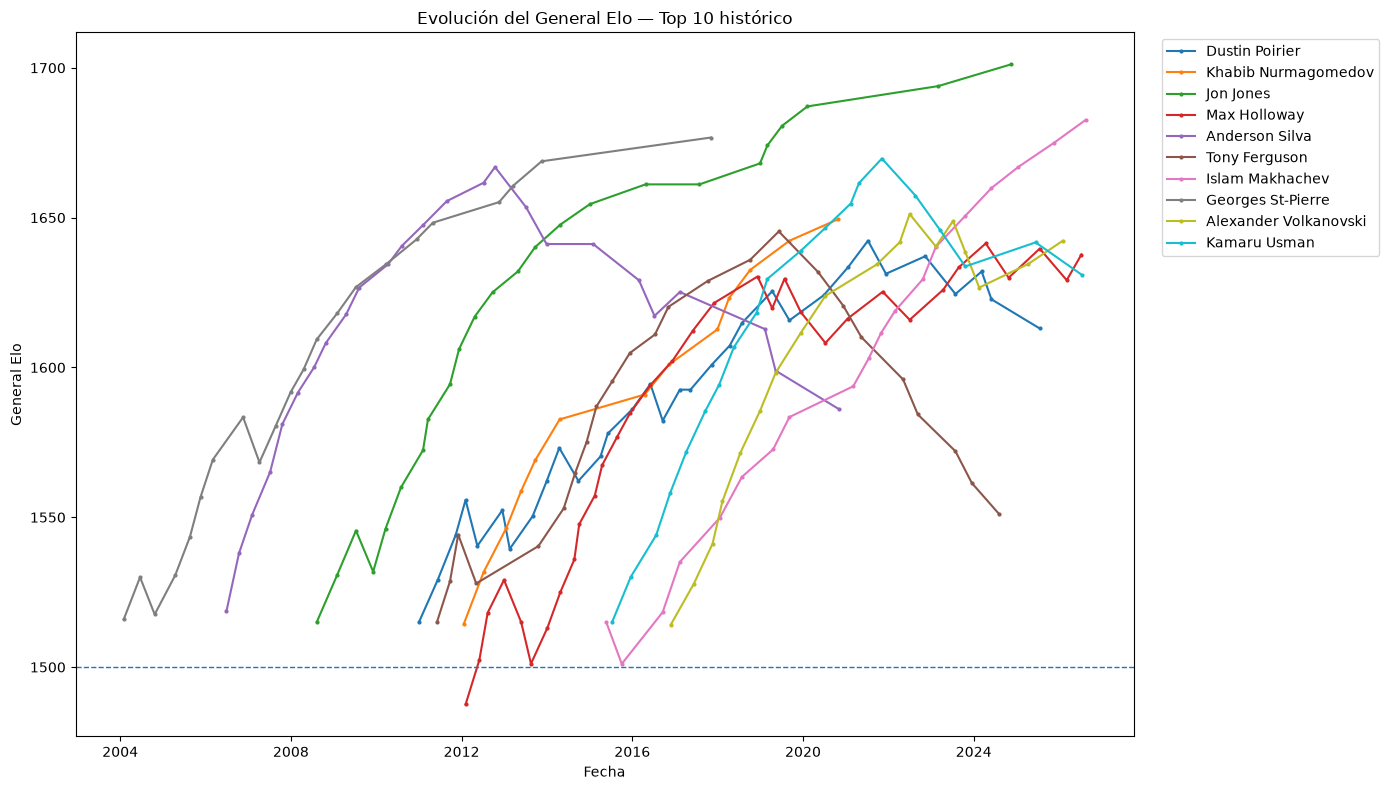

In [14]:
top_fighter_ids = (
    historical_peak
    .head(10)["fighter_id"]
    .tolist()
)

evolution = (
    post_points[
        post_points["fighter_id"].isin(top_fighter_ids)
    ]
    .sort_values(["fighter_id", "event_date"])
)

plt.figure(figsize=(14, 8))

for fighter_id, group in evolution.groupby("fighter_id"):
    name = group["fighter_name"].iloc[0]

    plt.plot(
        group["event_date"],
        group["elo"],
        marker="o",
        markersize=2,
        linewidth=1.5,
        label=name,
    )

plt.axhline(BASE_ELO, linestyle="--", linewidth=1)
plt.xlabel("Fecha")
plt.ylabel("General Elo")
plt.title("Evolución del General Elo — Top 10 histórico")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()
plt.show()

## 13. #1 P4P del modelo a lo largo del tiempo

Después de cada fecha con eventos UFC:

1. se actualiza el Elo de quienes combatieron;
2. se filtran luchadores activos durante los últimos `ACTIVE_WINDOW_DAYS`;
3. se exige `MIN_FIGHTS_CURRENT`;
4. se selecciona el mayor General Elo.

In [15]:
event_updates = (
    resolved[
        [
            "event_date", "event_id",
            "fighter_id", "fighter_name",
            "elo_general_raw_after",
            "fights_before",
        ]
    ]
    .sort_values(
        ["event_date", "event_id"],
        kind="stable",
    )
)

state: dict[str, dict[str, object]] = {}
leader_records: list[dict[str, object]] = []

for event_date, event_group in event_updates.groupby(
    "event_date",
    sort=True,
):
    event_date = pd.Timestamp(event_date)

    for row in event_group.itertuples(index=False):
        state[str(row.fighter_id)] = {
            "fighter_name": row.fighter_name,
            "elo": float(row.elo_general_raw_after),
            "last_fight_date": event_date,
            "ufc_fights": int(row.fights_before) + 1,
        }

    eligible = [
        (fighter_id, info)
        for fighter_id, info in state.items()
        if (
            (event_date - info["last_fight_date"]).days
            <= ACTIVE_WINDOW_DAYS
            and info["ufc_fights"] >= MIN_FIGHTS_CURRENT
        )
    ]

    if not eligible:
        continue

    leader_id, leader = max(
        eligible,
        key=lambda item: item[1]["elo"],
    )

    leader_records.append({
        "event_date": event_date,
        "fighter_id": leader_id,
        "fighter_name": leader["fighter_name"],
        "elo": leader["elo"],
    })

p4p_leader_timeline = pd.DataFrame(leader_records)

display(p4p_leader_timeline.tail(20))

,event_date,fighter_id,fighter_name,elo
764,2026-04-18,07f72a2a7591b409,Jon Jones,"1,701.16"
765,2026-04-25,07f72a2a7591b409,Jon Jones,"1,701.16"
766,2026-05-02,07f72a2a7591b409,Jon Jones,"1,701.16"
767,2026-05-09,07f72a2a7591b409,Jon Jones,"1,701.16"
768,2026-05-16,07f72a2a7591b409,Jon Jones,"1,701.16"
769,2026-05-30,07f72a2a7591b409,Jon Jones,"1,701.16"
770,2026-06-06,07f72a2a7591b409,Jon Jones,"1,701.16"
771,2026-06-14,07f72a2a7591b409,Jon Jones,"1,701.16"
772,2026-06-20,07f72a2a7591b409,Jon Jones,"1,701.16"
773,2026-06-27,07f72a2a7591b409,Jon Jones,"1,701.16"


In [16]:
if not p4p_leader_timeline.empty:
    leader_periods = p4p_leader_timeline.copy()

    leader_periods["new_period"] = (
        leader_periods["fighter_id"]
        .ne(leader_periods["fighter_id"].shift())
    )

    leader_periods["period_id"] = (
        leader_periods["new_period"].cumsum()
    )

    leader_periods = (
        leader_periods
        .groupby(
            ["period_id", "fighter_id", "fighter_name"],
            as_index=False,
        )
        .agg(
            start_date=("event_date", "min"),
            end_date=("event_date", "max"),
            max_elo=("elo", "max"),
        )
        .sort_values("start_date")
    )

    display(leader_periods.tail(30))

,period_id,fighter_id,fighter_name,start_date,end_date,max_elo
0,1,429e7d3725852ce9,Royce Gracie,1994-03-11,1997-02-07,"1,599.18"
1,2,271fe91f4ba9d2c5,Don Frye,1997-05-30,1998-10-16,"1,594.80"
2,3,c670aa48827d6be6,Dan Severn,1999-01-08,1999-01-08,"1,577.30"
3,4,0aa92558424ced9e,Randy Couture,1999-03-05,1999-05-07,"1,559.32"
4,5,cedfdf8d423d500c,Pat Miletich,1999-07-16,1999-07-16,"1,566.84"
5,6,fcaae0385b514f11,Frank Shamrock,1999-09-24,2000-04-14,"1,568.57"
6,7,cedfdf8d423d500c,Pat Miletich,2000-06-09,2001-02-23,"1,587.13"
7,8,0aa92558424ced9e,Randy Couture,2001-05-04,2002-07-13,"1,596.54"
8,9,2f732dd9210d301f,Tito Ortiz,2002-09-27,2003-06-06,"1,587.25"
9,10,0aa92558424ced9e,Randy Couture,2003-09-26,2004-01-31,"1,591.35"


## 14. Peleas por el título

`clean_ufcstats_data.py` conserva `bout_type` si existe en los datos scrapeados.

Clasificación usada:

- `undisputed`: UFC Title Bout estándar.
- `interim`: Interim UFC Title Bout.
- `bmf`: BMF Title Bout.
- `other_title`: otros tipos de peleas cuyo `bout_type` contiene `Title Bout`.

### Qué podemos afirmar con esta BDD

Podemos identificar de forma reproducible:

- ganadores de title bouts;
- número de victorias en title bouts;
- peleadores que han ganado al menos un title bout;
- categorías en las que lo hicieron.

### Qué no reconstruimos de forma exacta

No inferimos automáticamente:

- días exactos de reinado;
- stripping;
- cinturones vacantes fuera de una pelea;
- cambios administrativos.

Para eso haría falta una fuente específica de historial de cinturones.

In [17]:
def classify_title_type(bout_type: object) -> str | None:
    if pd.isna(bout_type):
        return None

    text = str(bout_type).strip().lower()

    if "title bout" not in text:
        return None

    if "interim" in text:
        return "interim"

    if "bmf" in text:
        return "bmf"

    if "ufc" in text:
        return "undisputed"

    return "other_title"


fights["title_type"] = (
    fights["bout_type"].map(classify_title_type)
)

fights["is_title_bout"] = (
    fights["title_type"].notna()
)

title_bouts = fights[
    fights["is_title_bout"]
    & fights["winner_id"].notna()
].copy()

name_lookup = (
    fight_long[
        ["fighter_id", "fighter_name"]
    ]
    .drop_duplicates("fighter_id")
    .set_index("fighter_id")["fighter_name"]
)

title_bouts["winner_id"] = (
    title_bouts["winner_id"].astype("string")
)

title_bouts["winner_name"] = (
    title_bouts["winner_id"].map(name_lookup)
)

print("Columna bout_type disponible:", fights["bout_type"].notna().any())
print("Title bouts resueltos detectados:", len(title_bouts))

if len(title_bouts):
    display(
        title_bouts[
            [
                "event_date", "event_name",
                "weight_class", "bout_type",
                "title_type", "winner_name",
            ]
        ]
        .sort_values("event_date", ascending=False)
        .head(20)
    )
else:
    print(
        "No se han detectado title bouts. "
        "Comprueba que bout_type esté presente en fights_clean.parquet."
    )

NameError: name 'fight_long' is not defined

### 14.1. Peleadores con más victorias en Title Bouts

In [ ]:
if len(title_bouts):
    title_wins = (
        title_bouts
        .groupby(
            ["winner_id", "winner_name"],
            as_index=False,
        )
        .agg(
            title_bout_wins=("fight_id", "nunique"),
            first_title_win=("event_date", "min"),
            last_title_win=("event_date", "max"),
        )
        .sort_values(
            ["title_bout_wins", "last_title_win"],
            ascending=[False, False],
        )
        .reset_index(drop=True)
    )

    title_wins.insert(
        0,
        "rank",
        np.arange(1, len(title_wins) + 1),
    )

    display(title_wins.head(TOP_N))
else:
    title_wins = pd.DataFrame()

### 14.2. Ganadores históricos de UFC Title Bouts por categoría

Esto lista luchadores que han ganado al menos una pelea clasificada como `undisputed`.

**No equivale por sí solo a reconstruir todos los reinados administrativos**, pero sí proporciona una base sólida de campeones/ganadores de cinturón a partir de los resultados.

In [ ]:
undisputed_title_bouts = title_bouts[
    title_bouts["title_type"].eq("undisputed")
].copy()

historical_champions_by_division = (
    undisputed_title_bouts[
        [
            "weight_class", "winner_id",
            "winner_name", "event_date",
            "event_name",
        ]
    ]
    .sort_values("event_date")
    .drop_duplicates(
        ["weight_class", "winner_id"],
        keep="first",
    )
)

if len(historical_champions_by_division):
    for division in sorted(
        historical_champions_by_division[
            "weight_class"
        ].dropna().unique()
    ):
        table = historical_champions_by_division[
            historical_champions_by_division[
                "weight_class"
            ].eq(division)
        ]

        display(Markdown(f"### {division}"))

        display(
            table[
                [
                    "winner_name",
                    "event_date",
                    "event_name",
                ]
            ].rename(columns={
                "winner_name": "fighter_name",
                "event_date": "first_undisputed_title_bout_win",
            })
        )
else:
    print("No hay UFC Title Bouts estándar detectados.")

## 15. País y región

El pipeline actual de `fighters_clean.parquet` no exige país/nacionalidad.

Esta sección intenta:

1. usar `country` / `nationality` / `country_name` si alguna existe en `fighters_clean`;
2. usar `region` / `macro_region` / `zone` si existe;
3. si no, cargar `data/external/fighter_geography.csv`.

Formato recomendado:

| fighter_id | fighter_name | country | region |
|---|---|---|---|
| ... | ... | ... | ... |

La columna `region` se deja explícita para que puedas decidir el criterio: Europa, Cáucaso, Norteamérica, Latinoamérica, etc., sin inferencias ambiguas.

In [ ]:
GEO_PATH = EXTERNAL_DIR / "fighter_geography.csv"

COUNTRY_CANDIDATES = [
    "country",
    "nationality",
    "country_name",
]

REGION_CANDIDATES = [
    "region",
    "macro_region",
    "zone",
]


def first_existing(
    columns: list[str],
    df: pd.DataFrame,
) -> str | None:
    return next(
        (c for c in columns if c in df.columns),
        None,
    )


country_col = first_existing(
    COUNTRY_CANDIDATES,
    fighters,
)

region_col = first_existing(
    REGION_CANDIDATES,
    fighters,
)

if country_col is not None:
    geography = fighters[
        ["fighter_id", "fighter_name", country_col]
    ].copy()

    geography = geography.rename(
        columns={country_col: "country"}
    )

    if region_col is not None:
        geography["region"] = fighters[region_col]
    else:
        geography["region"] = pd.NA

    print(
        "Geografía tomada de fighters_clean.parquet:",
        f"country={country_col!r}, region={region_col!r}",
    )

elif GEO_PATH.exists():
    geography = pd.read_csv(
        GEO_PATH,
        dtype="string",
    )

    require_columns(
        geography,
        {
            "fighter_id",
            "fighter_name",
            "country",
            "region",
        },
        str(GEO_PATH),
    )

    print("Geografía tomada de:", GEO_PATH)

else:
    geography = None

    print(
        "No existe todavía información de país/región.\n"
        f"Puedes crear: {GEO_PATH}"
    )

### 15.1. Generar automáticamente una plantilla de geografía

Cambia `CREATE_GEOGRAPHY_TEMPLATE = True` una vez para crear un CSV con todos los peleadores. Después solo tienes que completar `country` y `region`.

In [ ]:
CREATE_GEOGRAPHY_TEMPLATE = False

if CREATE_GEOGRAPHY_TEMPLATE:
    EXTERNAL_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    geo_template = (
        fight_long[
            ["fighter_id", "fighter_name"]
        ]
        .drop_duplicates("fighter_id")
        .sort_values("fighter_name")
        .assign(
            country=pd.NA,
            region=pd.NA,
        )
    )

    if GEO_PATH.exists():
        raise FileExistsError(
            f"Ya existe {GEO_PATH}. "
            "No se sobrescribe automáticamente."
        )

    geo_template.to_csv(
        GEO_PATH,
        index=False,
    )

    print("Plantilla creada:", GEO_PATH)
    display(geo_template.head(20))

### 15.2. Campeones por país

In [ ]:
if geography is not None:
    geo = geography.copy()

    geo["fighter_id"] = (
        geo["fighter_id"].astype("string")
    )

    champions_geo = (
        historical_champions_by_division
        .merge(
            geo[
                [
                    "fighter_id",
                    "country",
                    "region",
                ]
            ],
            left_on="winner_id",
            right_on="fighter_id",
            how="left",
        )
    )

    champions_by_country = (
        champions_geo[
            champions_geo["country"].notna()
        ]
        .groupby("country", as_index=False)
        .agg(
            unique_champions=("winner_id", "nunique"),
            divisions_with_champion=("weight_class", "nunique"),
        )
        .sort_values(
            [
                "unique_champions",
                "divisions_with_champion",
            ],
            ascending=[False, False],
        )
        .reset_index(drop=True)
    )

    display(champions_by_country)
else:
    print(
        "Añade country/region para activar este análisis."
    )

### 15.3. Campeones por región

In [ ]:
if geography is not None:
    champions_by_region = (
        champions_geo[
            champions_geo["region"].notna()
        ]
        .groupby("region", as_index=False)
        .agg(
            unique_champions=("winner_id", "nunique"),
            divisions_with_champion=("weight_class", "nunique"),
        )
        .sort_values(
            [
                "unique_champions",
                "divisions_with_champion",
            ],
            ascending=[False, False],
        )
        .reset_index(drop=True)
    )

    display(champions_by_region)
else:
    print(
        "Añade country/region para activar este análisis."
    )

### 15.4. Más estadísticas por país

Además de campeones:

- número de peleadores UFC;
- peleadores activos;
- mejor Peak Elo;
- Elo actual medio de peleadores activos.

In [ ]:
if geography is not None:
    all_fighters_geo = (
        fight_long[
            ["fighter_id", "fighter_name"]
        ]
        .drop_duplicates("fighter_id")
        .merge(
            geo[
                [
                    "fighter_id",
                    "country",
                    "region",
                ]
            ],
            on="fighter_id",
            how="left",
        )
    )

    fighter_country_stats = (
        all_fighters_geo[
            all_fighters_geo["country"].notna()
        ]
        .groupby("country", as_index=False)
        .agg(
            ufc_fighters=("fighter_id", "nunique")
        )
    )

    active_geo = (
        current_active
        .merge(
            geo[
                [
                    "fighter_id",
                    "country",
                    "region",
                ]
            ],
            on="fighter_id",
            how="left",
        )
    )

    active_country_stats = (
        active_geo[
            active_geo["country"].notna()
        ]
        .groupby("country", as_index=False)
        .agg(
            active_fighters=("fighter_id", "nunique"),
            mean_current_elo=("current_elo", "mean"),
            best_current_elo=("current_elo", "max"),
        )
    )

    peak_geo = (
        historical_peak
        .merge(
            geo[
                [
                    "fighter_id",
                    "country",
                    "region",
                ]
            ],
            on="fighter_id",
            how="left",
        )
    )

    peak_country_stats = (
        peak_geo[
            peak_geo["country"].notna()
        ]
        .groupby("country", as_index=False)
        .agg(
            best_peak_elo=("peak_elo", "max")
        )
    )

    country_summary = (
        fighter_country_stats
        .merge(
            active_country_stats,
            on="country",
            how="left",
        )
        .merge(
            peak_country_stats,
            on="country",
            how="left",
        )
        .merge(
            champions_by_country[
                ["country", "unique_champions"]
            ],
            on="country",
            how="left",
        )
    )

    country_summary["unique_champions"] = (
        country_summary["unique_champions"]
        .fillna(0)
        .astype(int)
    )

    country_summary["champion_rate"] = (
        country_summary["unique_champions"]
        / country_summary["ufc_fighters"]
    )

    country_summary = country_summary.sort_values(
        [
            "unique_champions",
            "best_peak_elo",
        ],
        ascending=[False, False],
    )

    display(country_summary)
else:
    print(
        "Añade country/region para activar este análisis."
    )

## 16. Récords y curiosidades

### 16.1. Mayores upsets según Elo

Entre las victorias, buscamos los casos en los que el ganador tenía menor probabilidad esperada según el Elo pre-fight.

In [ ]:
upsets = (
    ratings[
        ratings["result"].eq("W")
    ]
    [
        [
            "event_date", "event_name",
            "fighter_name", "opponent_name",
            "weight_class",
            "elo_general_raw_before",
            "opponent_elo_before",
            "expected_score",
            "elo_change",
        ]
    ]
    .sort_values(
        "expected_score",
        ascending=True,
    )
    .reset_index(drop=True)
)

upsets["elo_implied_win_probability"] = (
    upsets["expected_score"]
)

display(
    upsets[
        [
            "event_date", "fighter_name",
            "opponent_name", "weight_class",
            "elo_general_raw_before",
            "opponent_elo_before",
            "elo_implied_win_probability",
            "elo_change",
        ]
    ].head(20)
)

### 16.2. Mayores subidas de Elo en una pelea

In [ ]:
biggest_elo_gains = (
    ratings[
        ratings["result"].eq("W")
    ]
    [
        [
            "event_date", "event_name",
            "fighter_name", "opponent_name",
            "weight_class",
            "elo_general_raw_before",
            "opponent_elo_before",
            "elo_change",
            "elo_general_raw_after",
        ]
    ]
    .sort_values(
        "elo_change",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(biggest_elo_gains.head(20))

### 16.3. Mayores rachas de victorias UFC detectadas

In [ ]:
max_win_streak = (
    ratings
    .groupby(
        ["fighter_id", "fighter_name"],
        as_index=False,
    )
    .agg(
        max_ufc_win_streak=("win_streak_after", "max")
    )
    .sort_values(
        "max_ufc_win_streak",
        ascending=False,
    )
    .reset_index(drop=True)
)

max_win_streak["max_ufc_win_streak"] = (
    max_win_streak["max_ufc_win_streak"]
    .fillna(0)
    .astype(int)
)

display(max_win_streak.head(20))

### 16.4. Tiempo aproximado como #1 P4P del modelo

Se imputa al líder de cada fecha el tiempo hasta la siguiente fecha con evento resuelto. Es una medida de **tiempo calendario aproximado** como líder del modelo.

In [ ]:
if not p4p_leader_timeline.empty:
    leader_time = p4p_leader_timeline.copy()

    leader_time["next_event_date"] = (
        leader_time["event_date"].shift(-1)
    )

    leader_time.loc[
        leader_time.index[-1],
        "next_event_date",
    ] = latest_resolved_date

    leader_time["days_as_no1_interval"] = (
        leader_time["next_event_date"]
        - leader_time["event_date"]
    ).dt.days.clip(lower=0)

    days_as_no1 = (
        leader_time
        .groupby(
            ["fighter_id", "fighter_name"],
            as_index=False,
        )
        .agg(
            approx_days_as_model_no1=(
                "days_as_no1_interval",
                "sum",
            ),
            highest_no1_elo=("elo", "max"),
        )
        .sort_values(
            "approx_days_as_model_no1",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    display(days_as_no1.head(20))

## 17. Resumen final

In [ ]:
summary = {
    "latest_resolved_fight_date": latest_resolved_date.date(),
    "active_cutoff": active_cutoff.date(),
    "fighters_with_elo_history": post_points["fighter_id"].nunique(),
    "active_ranked_fighters": len(current_active),
    "historical_peak_no1": (
        historical_peak.iloc[0]["fighter_name"]
        if len(historical_peak)
        else None
    ),
    "historical_peak_no1_elo": (
        float(historical_peak.iloc[0]["peak_elo"])
        if len(historical_peak)
        else None
    ),
    "current_model_p4p_no1": (
        current_active.iloc[0]["fighter_name"]
        if len(current_active)
        else None
    ),
    "current_model_p4p_no1_elo": (
        float(current_active.iloc[0]["current_elo"])
        if len(current_active)
        else None
    ),
    "resolved_title_bouts_detected": int(len(title_bouts)),
    "geography_available": geography is not None,
}

display(pd.Series(summary, name="value").to_frame())

## Ideas para ampliar este notebook

- Comparar **P4P oficial de UFC vs P4P Elo** si se incorpora un histórico oficial.
- Incorporar un dataset específico de reinados para calcular:
  - días como campeón;
  - defensas consecutivas;
  - número de reinados;
  - campeón más joven / veterano.
- Visualizar campeones por país en un mapa.
- Ranking histórico por década.
- Evolución de la fuerza media de cada categoría.
- Elo medio por país o región a lo largo del tiempo.
- Separar análisis masculino/femenino si se normalizan las divisiones.